# MMP (mitochondrial toxicity) -- 10-fold CV ROC/PR curves, all 13 models

Pools the out-of-fold test predictions across all 10 LOO folds (folds are disjoint and together cover every compound exactly once), then plots ONE ROC curve and ONE PR curve per model from the pooled predictions -- matching the style of the existing single-split figure, but for the 10-fold evaluation.

Requires `data_loo/fold_<i>/y_test.npy` (pulled from Wahab -- not regenerated locally, to avoid the RDKit-version split-mismatch issue found earlier this session) and `results_loo/probs/<model>_fold<i>_test_probs.npy` (already present locally).

Consensus groups (MV-GNN excluded, per instruction -- it's reserved for the separate reviewer-facing comparison only):
- Consensus-Classical = mean(RF, SVM, XGBoost)
- Consensus-GNN = mean(GCN, GAT, GIN, SAGE)
- Consensus-GT = mean(Graphormer, GraphGPS)
- Consensus (Full) = mean(all 9 above)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

HERE = os.getcwd()
DATA_LOO = os.path.join(HERE, 'data_loo')
PROBS_DIR = os.path.join(HERE, 'results_loo', 'probs')
N_FOLDS = 10

INDIVIDUAL = {
    'Random Forest': 'rf', 'SVM': 'svm', 'XGBoost': 'xgb',
    'GCN': 'gcn', 'GAT': 'gat', 'GIN': 'gin', 'SAGE': 'sage',
    'Graphormer': 'graphormer', 'GraphGPS': 'graphgps',
}
CLASSICAL = ['Random Forest', 'SVM', 'XGBoost']
GNN = ['GCN', 'GAT', 'GIN', 'SAGE']
GT = ['Graphormer', 'GraphGPS']
CONSENSUS_GROUPS = {
    'Consensus-Classical': CLASSICAL,
    'Consensus-GNN': GNN,
    'Consensus-GT': GT,
    'Consensus': CLASSICAL + GNN + GT,
}

In [2]:
missing = []
for i in range(N_FOLDS):
    p = os.path.join(DATA_LOO, f'fold_{i}', 'y_test.npy')
    if not os.path.exists(p):
        missing.append(p)
if missing:
    raise FileNotFoundError(
        'Missing per-fold y_test.npy (pull from Wahab first, see chat for the rsync command):\n' +
        '\n'.join(missing)
    )
print('All 10 per-fold y_test.npy files found.')

All 10 per-fold y_test.npy files found.


In [3]:
# Pool out-of-fold predictions: concatenate all 10 folds in the SAME order for
# every model and for y_true, so arrays stay aligned compound-for-compound.
y_true_parts = [np.load(os.path.join(DATA_LOO, f'fold_{i}', 'y_test.npy')) for i in range(N_FOLDS)]
y_true = np.concatenate(y_true_parts)

pooled_probs = {}
for disp, prefix in INDIVIDUAL.items():
    parts = [np.load(os.path.join(PROBS_DIR, f'{prefix}_fold{i}_test_probs.npy')) for i in range(N_FOLDS)]
    pooled_probs[disp] = np.concatenate(parts)
    assert len(pooled_probs[disp]) == len(y_true), f'{disp}: length mismatch'

for name, members in CONSENSUS_GROUPS.items():
    pooled_probs[name] = np.mean([pooled_probs[m] for m in members], axis=0)

print(f'Pooled {len(y_true)} compounds across {N_FOLDS} folds.')
print(f'Prevalence (active fraction): {y_true.mean():.4f}')

Pooled 5937 compounds across 10 folds.
Prevalence (active fraction): 0.1443


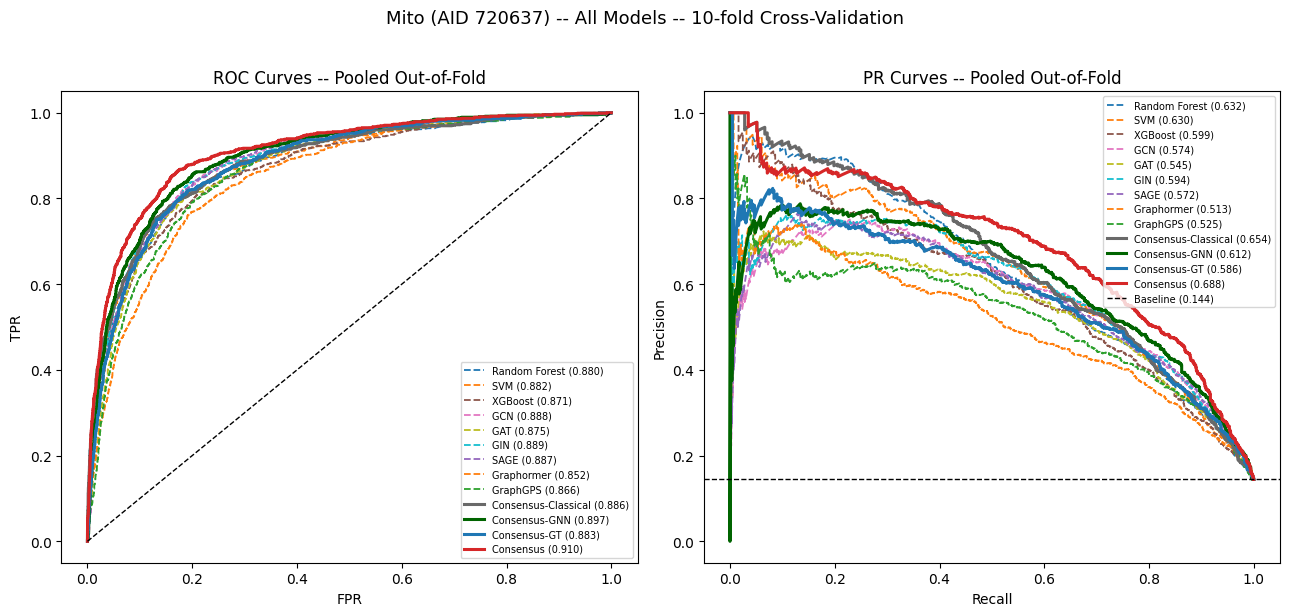

Saved -> figures/test_set_performance_mito_10fold.png


In [4]:
# Plot order and colors matching the project's established group convention:
# classical (dashed), GNN (dashed), GT (dashed), then consensus groups (solid, bolder)
PLOT_ORDER = CLASSICAL + GNN + GT + ['Consensus-Classical', 'Consensus-GNN', 'Consensus-GT', 'Consensus']
COLORS = {
    'Random Forest': 'tab:blue', 'SVM': 'tab:orange', 'XGBoost': 'tab:brown',
    'GCN': 'tab:pink', 'GAT': 'tab:olive', 'GIN': 'tab:cyan', 'SAGE': 'tab:purple',
    'Graphormer': 'tab:orange', 'GraphGPS': 'tab:green',
    'Consensus-Classical': 'dimgray', 'Consensus-GNN': 'darkgreen',
    'Consensus-GT': 'tab:blue', 'Consensus': 'tab:red',
}
SOLID = {'Consensus-Classical', 'Consensus-GNN', 'Consensus-GT', 'Consensus'}

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle('Mito (AID 720637) -- All Models -- 10-fold Cross-Validation', y=1.02, fontsize=13)

for name in PLOT_ORDER:
    prob = pooled_probs[name]
    fpr, tpr, _ = roc_curve(y_true, prob)
    auc = roc_auc_score(y_true, prob)
    lw = 2.2 if name in SOLID else 1.3
    ls = '-' if name in SOLID else '--'
    ax_roc.plot(fpr, tpr, label=f'{name} ({auc:.3f})', color=COLORS[name], linewidth=lw, linestyle=ls)

ax_roc.plot([0, 1], [0, 1], 'k--', linewidth=1, label=None)
ax_roc.set_xlabel('FPR')
ax_roc.set_ylabel('TPR')
ax_roc.set_title('ROC Curves -- Pooled Out-of-Fold')
ax_roc.legend(fontsize=7, loc='lower right')

baseline = y_true.mean()
for name in PLOT_ORDER:
    prob = pooled_probs[name]
    prec, rec, _ = precision_recall_curve(y_true, prob)
    ap = average_precision_score(y_true, prob)
    lw = 2.2 if name in SOLID else 1.3
    ls = '-' if name in SOLID else '--'
    ax_pr.plot(rec, prec, label=f'{name} ({ap:.3f})', color=COLORS[name], linewidth=lw, linestyle=ls)

ax_pr.axhline(baseline, color='k', linestyle='--', linewidth=1, label=f'Baseline ({baseline:.3f})')
ax_pr.set_xlabel('Recall')
ax_pr.set_ylabel('Precision')
ax_pr.set_title('PR Curves -- Pooled Out-of-Fold')
ax_pr.legend(fontsize=7, loc='upper right')

plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/test_set_performance_mito_10fold.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved -> figures/test_set_performance_mito_10fold.png')

**Note on AUC values**: these are computed on the *pooled* out-of-fold predictions (all 10 folds concatenated into one array, then one ROC-AUC/PR-AUC computed), which is the standard way to draw a single combined curve for cross-validation. This is a slightly different statistic from the *mean of the 10 per-fold AUCs* reported in the main results table (`tab:mito_results`) -- the two will be close but not necessarily identical. If you need the legend values to match the table exactly, that would require averaging 10 separate curves (interpolated to a common grid) instead of pooling, which is a different and noisier plot; pooling is what the original single-split figure effectively did too, so this keeps the same convention.